In [94]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline 
from sklearn.metrics import r2_score
from sklearn.model_selection import cross_val_score
df= pd.read_csv("Sales Data Analysis.csv")
print(df[["Column1","Order ID"]].head(10))
df.shape

   Column1  Order ID
0        0    295665
1        1    295666
2        2    295667
3        3    295668
4        4    295669
5        5    295670
6        6    295671
7        7    295672
8        8    295673
9        9    295674


(185950, 13)

In [95]:
df_cleaned= df.drop(columns=["Column1","Order ID","Order Date","Purchase Address","Month","City","Time of Day"])
print(df_cleaned)

             Product Category                 Product  Quantity Ordered  \
0       Laptops and Computers      Macbook Pro Laptop                 1   
1             Home Appliances      LG Washing Machine                 1   
2             Charging Cables    USB-C Charging Cable                 1   
3                    Monitors        27in FHD Monitor                 1   
4             Charging Cables    USB-C Charging Cable                 1   
...                       ...                     ...               ...   
185945               Batterie  AAA Batteries (4-pack)                 1   
185946               Monitors        27in FHD Monitor                 1   
185947        Charging Cables    USB-C Charging Cable                 1   
185948        Charging Cables    USB-C Charging Cable                 1   
185949               Batterie  AAA Batteries (4-pack)                 1   

        Price Each    Sales  Hour  
0          1700.00  1700.00     0  
1           600.00   600.00

In [96]:
print(df_cleaned.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 185950 entries, 0 to 185949
Data columns (total 6 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Product Category  185950 non-null  object 
 1   Product           185950 non-null  object 
 2   Quantity Ordered  185950 non-null  int64  
 3   Price Each        185950 non-null  float64
 4   Sales             185950 non-null  float64
 5   Hour              185950 non-null  int64  
dtypes: float64(2), int64(2), object(2)
memory usage: 8.5+ MB
None


In [97]:
df_cleaned.isnull().mean()*100

Product Category    0.0
Product             0.0
Quantity Ordered    0.0
Price Each          0.0
Sales               0.0
Hour                0.0
dtype: float64

In [98]:
df_cleaned.duplicated().sum()

np.int64(184958)

In [111]:
df_cleaned["Product"].value_counts()

Product
USB-C Charging Cable          21903
Lightning Charging Cable      21658
AAA Batteries (4-pack)        20641
AA Batteries (4-pack)         20577
Wired Headphones              18882
Apple Airpods Headphones      15549
Bose SoundSport Headphones    13325
27in FHD Monitor               7507
iPhone                         6842
27in 4K Gaming Monitor         6230
34in Ultrawide Monitor         6181
Google Phone                   5525
Flatscreen TV                  4800
Macbook Pro Laptop             4724
ThinkPad Laptop                4128
20in Monitor                   4101
Vareebadd Phone                2065
LG Washing Machine              666
LG Dryer                        646
Name: count, dtype: int64

In [113]:
df_cleaned.groupby("Product")["Sales"].nunique()

Product
20in Monitor                  2
27in 4K Gaming Monitor        2
27in FHD Monitor              2
34in Ultrawide Monitor        2
AA Batteries (4-pack)         7
AAA Batteries (4-pack)        9
Apple Airpods Headphones      3
Bose SoundSport Headphones    3
Flatscreen TV                 2
Google Phone                  2
LG Dryer                      1
LG Washing Machine            1
Lightning Charging Cable      4
Macbook Pro Laptop            2
ThinkPad Laptop               2
USB-C Charging Cable          6
Vareebadd Phone               2
Wired Headphones              4
iPhone                        2
Name: Sales, dtype: int64

In [99]:
df_cleaned[["Quantity Ordered","Price Each","Sales","Hour"]].skew()

Quantity Ordered    4.833164
Price Each          2.872149
Sales               2.881913
Hour               -0.530377
dtype: float64

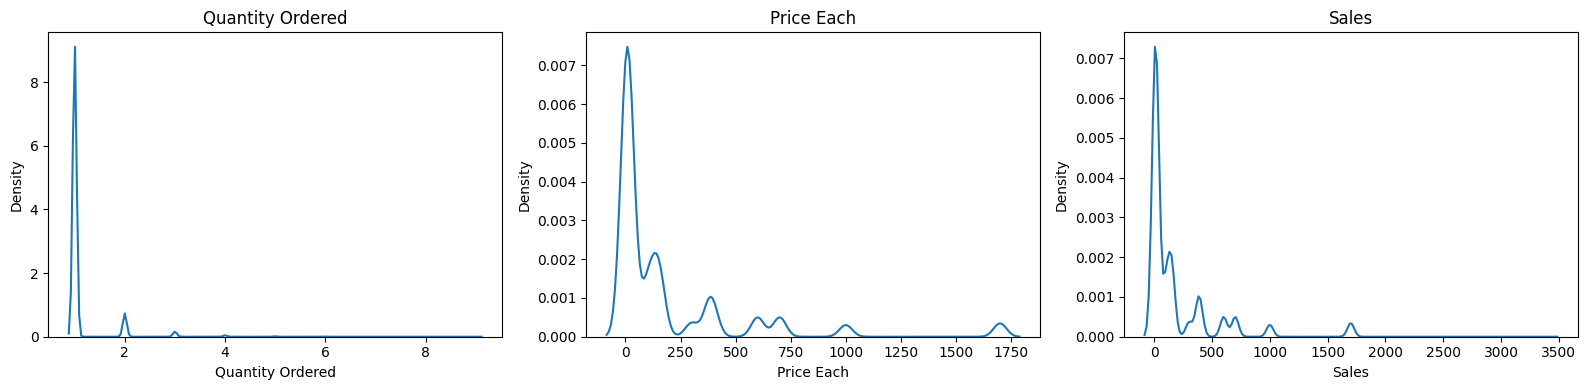

In [100]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
cols=["Quantity Ordered","Price Each","Sales"]
for i,col in enumerate(cols):
    sns.kdeplot(df_cleaned[col],ax=ax[i])
    ax[i].set_title(col)
plt.tight_layout()
plt.show()

In [101]:
X=df_cleaned.drop(columns=["Sales","Quantity Ordered","Price Each"])
y=df_cleaned["Sales"]

In [102]:
X_train,X_test,y_train,y_test= train_test_split(X,y,test_size=0.2,random_state=42)

In [103]:
y_train.shape

(148760,)

In [104]:
trf= ColumnTransformer([
    ('Encoder',OneHotEncoder(sparse_output=False,handle_unknown='ignore'),[0,1])
],remainder="passthrough")

In [105]:
trf1= ColumnTransformer([
    ('transformation',FunctionTransformer(np.log1p),[2,3,4])
],remainder="passthrough")

In [106]:
trf2= LinearRegression()
pipe=Pipeline([('trf',trf),('trf1',trf1),('trf2',trf2)])


In [107]:
pipe.fit(X_train,y_train)

,steps,"[('trf', ...), ('trf1', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('Encoder', ...)]"
,remainder,'passthrough'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [108]:
y_pred= pipe.predict(X_test)
print(r2_score(y_test,y_pred))

0.9992354157130837


In [109]:
np.mean(cross_val_score(pipe,X,y,scoring='r2',cv=10))

np.float64(0.9984126461019315)